# Group theory 1: Symmetry

*Learning path: group theory, part 1 of 3.* [Index](README.md) · Next: [Cyclic groups](02-cyclic-groups.ipynb)

A group is the mathematics of symmetry. The idea came from Galois (around 1830), who used it to show that there is no
formula like the quadratic formula for equations of degree 5. Today groups describe crystals, the particles of physics,
the Rubik's cube and the cryptography of lesson 4 of the number theory path. In this lesson you will learn

* what a symmetry is, and how to write one as a **permutation**,
* how to **compose** symmetries, and why the order matters,
* the four rules (axioms) that make a collection of symmetries a **group**,
* the **group table** (Cayley table), the **order** of an element, and the symmetries of a square.

You only need the [foundations](../foundations/README.md) up to complex numbers; no algebra beyond that.

## 1. The symmetries of a triangle

A **symmetry** of a shape is a motion that puts it back on top of itself. An equilateral triangle has six:

* doing nothing (the **identity**),
* rotating by $120^\circ$ or by $240^\circ$ counter-clockwise,
* flipping it over one of the three mirror lines, each through a corner and the middle of the opposite side.

Number the corner positions 1 (top), 2 (bottom left) and 3 (bottom right). The plot shows the triangle, its three
mirror lines (mirror $k$ runs through corner $k$) and the three corners. The horizontal and vertical axes are ordinary $x$ and $y$ coordinates; the triangle
fits in the unit circle, with corner $k$ at angle $90^\circ + (k - 1)\cdot 120^\circ$.

The triangle is drawn as one closed curve in polar form: the point at angle $t$ (measured from the positive $x$-axis)
and distance $R(t)$ from the centre, for $t$ from 0 to $2\pi$, so `parametric(R*cos(t), R*sin(t), t, 0, 2*pi)`. For a
regular polygon with $n = 3$ sides and a corner at angle $\pi/2$,

$$R(t) = \frac{\cos(\pi/3)}{\cos\big(\pi/3 - \tfrac13\arccos\cos(3(t - \pi/2))\big)}.$$

Here $\arccos(\cos u)$ is a zigzag between 0 and $\pi$ that measures how far the direction $t$ is from the nearest
corner, and dividing by the cosine moves the point out to the straight side (1 at a corner, $\cos(\pi/3) = 1/2$ in the
middle of a side). The mirror lines are straight segments `parametric(s*cos(a), s*sin(a), s, -1/2, 1)` at angle $a$, from
the middle of a side ($s = -1/2$) through the centre to the opposite corner ($s = 1$), and `scatter` marks the corners, given as rows $[x\ y]$:

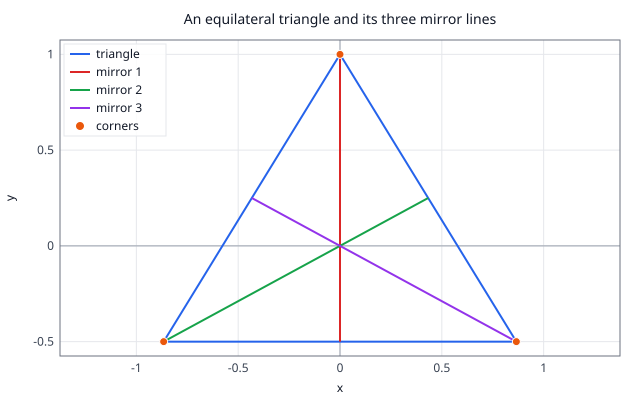

In [1]:
R = cos(pi/3)/cos(pi/3 - acos(cos(3*(t - pi/2)))/3);
tri = parametric(R*cos(t), R*sin(t), t, 0, 2*pi);
m1 = parametric(0, s, s, -1/2, 1);
m2 = parametric(s*cos(pi/2 + 2*pi/3), s*sin(pi/2 + 2*pi/3), s, -1/2, 1);
m3 = parametric(s*cos(pi/2 + 4*pi/3), s*sin(pi/2 + 4*pi/3), s, -1/2, 1);
corners = scatter([0 1; -sqrt(3)/2 -1/2; sqrt(3)/2 -1/2], [x y]);
p = legend(show(tri, m1, m2, m3, corners), "triangle", "mirror 1", "mirror 2", "mirror 3", "corners");
labels(title(p, "An equilateral triangle and its three mirror lines"), "x", "y")

## 2. Symmetries as permutations

A symmetry is completely described by where it sends each corner position. The rotation by $120^\circ$
counter-clockwise moves whatever is at position 1 to position 2, position 2 to 3, and 3 to 1. We write that as the
**cycle** $(1\ 2\ 3)$: "1 goes to 2 goes to 3 goes back to 1". The flip in the mirror line through corner 1 keeps 1
and swaps 2 and 3: the cycle $(2\ 3)$.

`perm("(1 2 3)", 3)` turns cycle notation into a **permutation** of $1, 2, 3$, written as the list of images: entry $i$
is where $i$ goes. `cycles(p)` turns it back:

In [2]:
r = perm("(1 2 3)", 3)
f = perm("(2 3)", 3)
cycles(r)

2	3	1
1	3	2
(1 2 3)

So $r = [2\ 3\ 1]$ means $1 \to 2$, $2 \to 3$, $3 \to 1$, and $f = [1\ 3\ 2]$ means $1 \to 1$, $2 \to 3$, $3 \to 2$.

## 3. Composing symmetries

Doing one symmetry after another is again a symmetry. `compose(p, q)` means **first $q$, then $p$** (the same order as
$p(q(x))$ for functions). Rotating twice is the rotation by $240^\circ$; three times is the identity; flipping twice is
the identity too:

In [3]:
compose(r, r)
compose(r, compose(r, r))
compose(f, f)

3	1	2
1	2	3
1	2	3

Now the surprise: first flip then rotate is **not** the same as first rotate then flip.

In [4]:
compose(r, f)
compose(f, r)
cycles(compose(r, f))
cycles(compose(f, r))

2	1	3
3	2	1
(1 2)
(1 3)

$r$ after $f$ is the flip $(1\ 2)$, and $f$ after $r$ is the flip $(1\ 3)$. You can check this with a paper triangle.
Symmetries, unlike numbers, do not **commute**: $rf \ne fr$.

Every symmetry can be undone. `pinverse(p)` gives the symmetry that undoes $p$. The inverse of the $120^\circ$
rotation is the $240^\circ$ rotation, and a flip is its own inverse:

In [5]:
pinverse(r)
pinverse(f)
compose(pinverse(r), r)

3	1	2
1	3	2
1	2	3

## 4. What a group is

A **group** is a collection of things (here: symmetries) with a way to combine two of them (here: `compose`) such that

1. combining two elements gives an element of the collection (**closure**);
2. $(ab)c = a(bc)$ (**associativity**; true for composing motions, since both mean "do $c$, then $b$, then $a$");
3. there is an **identity** $e$ with $ea = ae = a$;
4. every $a$ has an **inverse** $a^{-1}$ with $a^{-1}a = aa^{-1} = e$.

Commutativity is *not* required. Groups where $ab = ba$ always are called **abelian**, after Niels Henrik Abel.

`generate(g1, g2, ...)` composes the given elements with each other in every possible way until nothing new appears,
and lists the whole group, one element per row, the identity first. The rotation $r$ and the flip $f$ produce all six
symmetries of the triangle:

In [6]:
G = generate(r, f)

1	2	3
1	3	2
2	1	3
2	3	1
3	1	2
3	2	1

The rows are: 1 the identity, 2 the flip $(2\ 3)$, 3 the flip $(1\ 2)$, 4 the rotation $r = (1\ 2\ 3)$, 5 the rotation
$r^2 = (1\ 3\ 2)$, 6 the flip $(1\ 3)$. This group is called $D_3$, the **dihedral group** of the triangle. It is also
$S_3$, *all* permutations of three things: every rearrangement of the corners is a symmetry.

`G(k)` picks row $k$ of the table, so we can ask about each element in turn. Its **order** is how many times you must
repeat it to get back to the identity, and `porder` computes it. The table has one row per element of $G$:

In [7]:
table(porder(G(k)), k, 1, 6)

1	2	2	3	3	2

The identity has order 1, the flips order 2, the rotations order 3.

## 5. The group table

A group is completely described by its multiplication table. `cayley(G)` makes it: the entry in row $i$, column $j$ is
the row number of the element $G(i)$ composed after $G(j)$:

In [8]:
cayley(G)

1	2	3	4	5	6
2	1	5	6	3	4
3	4	1	2	6	5
4	3	6	5	1	2
5	6	2	1	4	3
6	5	4	3	2	1

How to read it: row 4 ($r$), column 2 ($f$) says 3, so $r$ after $f$ is element 3, the flip $(1\ 2)$, as we found
above. Row 2, column 4 says 6: $f$ after $r$ is the flip $(1\ 3)$. The table is not symmetric about its diagonal,
because the group is not abelian.

Two things to notice, true for every group table:

* every row and every column contains each element exactly once (a **Latin square**), because $ax = b$ has exactly one
  solution $x = a^{-1}b$;
* the four entries in rows and columns 1, 4, 5 form a smaller table of their own: the rotations $\{e, r, r^2\}$ are a
  group inside the group, a **subgroup**.

## 6. The symmetries of a square

A square has 8 symmetries: four rotations (by $0^\circ, 90^\circ, 180^\circ, 270^\circ$) and four flips (two mirror
lines through opposite corners, two through the middles of opposite sides). With the corners numbered 1 to 4 around
the square, the quarter turn is $(1\ 2\ 3\ 4)$ and the flip in the diagonal through corners 1 and 3 is $(2\ 4)$:

In [9]:
s = perm("(1 2 3 4)", 4);
d = perm("(2 4)", 4);
D4 = generate(s, d)
table([porder(D4(k)), psign(D4(k))], k, 1, 8)

1	2	3	4
1	4	3	2
2	1	4	3
2	3	4	1
3	2	1	4
3	4	1	2
4	1	2	3
4	3	2	1
1	1
2	-1
2	1
4	-1
2	-1
2	1
4	-1
2	1

The group $D_4$ has 8 elements. In the list, rows 1, 4, 6 and 7 are the rotations by $0^\circ$, $90^\circ$, $180^\circ$
and $270^\circ$; rows 2 and 5 are the flips in the diagonals, $(2\ 4)$ and $(1\ 3)$; rows 3 and 8 are the flips in the
lines through the middles of opposite sides, which swap two pairs of corners, such as $(1\ 2)(3\ 4)$.

The second table has one row per element: its order, and its **sign** (`psign`), which is $+1$ when the permutation can
be made from an even number of swaps and $-1$ for an odd number (lesson 3 explains why this is well defined). The
quarter turns have order 4; the half turn and all four flips have order 2. The sign does not tell rotations from flips
here: the quarter turn $(1\ 2\ 3\ 4)$ takes three swaps, so it is odd.

Not every permutation of the corners is a symmetry of the square: there are $4! = 24$ permutations of four corners but
only 8 symmetries. Swapping just corners 1 and 2, for instance, would tear the square apart. So $D_4$ is a subgroup of
the group $S_4$ of all 24 permutations, and $8$ divides $24$. That is no accident: lesson 3 proves that the size of a
subgroup always divides the size of the group.

In [10]:
size(generate(perm("(1 2 3 4)", 4), perm("(1 2)", 4)))

24	4

The rotation $(1\ 2\ 3\ 4)$ and the forbidden swap $(1\ 2)$ together generate all 24 permutations of $S_4$.

## Summary

* A symmetry is a permutation of corners: `perm("(1 2 3)", n)`, `cycles(p)`.
* `compose(p, q)` is "first $q$, then $p$"; it is not commutative. `pinverse(p)` undoes $p$.
* A group: closure, associativity, identity, inverses. `generate` builds the group from a few elements, `cayley` its
  table, `porder` the order of an element, `G(k)` picks element $k$.
* The triangle's group $D_3 = S_3$ has 6 elements; the square's $D_4$ has 8.

**Try it:** the regular pentagon: generate its group from `perm("(1 2 3 4 5)", 5)` and the flip `perm("(2 5)(3 4)", 5)`.
How many elements, and which orders occur? A rectangle that is not a square has only 4 symmetries: find them as
permutations of the corners and make their table. Is that group abelian?

Next: [Cyclic groups](02-cyclic-groups.ipynb), the simplest groups of all, and their link with modular arithmetic.

## Sources

1. É. Galois, "Mémoire sur les conditions de résolubilité des équations par radicaux" (1830, published by Liouville in 1846).
2. A. Cayley, "On the theory of groups, as depending on the symbolic equation θⁿ = 1", *Philosophical Magazine* 7 (1854) 40–47.
3. M. A. Armstrong, *Groups and Symmetry*, Springer (1988). Chapters 1–5.
4. N. Carter, *Visual Group Theory*, Mathematical Association of America (2009).